# Problem Statement

## **Business Context**

Pneumonia is one of the leading causes of morbidity and mortality worldwide, particularly affecting children under five years and elderly populations. According to the World Health Organization (WHO), pneumonia accounts for a significant percentage of deaths caused by infectious diseases. Early detection and timely treatment are critical to improving patient outcomes, yet current diagnostic methods present challenges.

The most common method for diagnosing pneumonia is through clinical evaluation combined with chest X-ray imaging. However, accurate interpretation of X-rays requires skilled radiologists, whose availability is limited in many regions, especially in rural or resource-constrained healthcare settings. Even when radiologists are available, factors such as fatigue, high patient load, and human error can affect the accuracy and consistency of diagnosis. This may lead to delayed treatment, misdiagnosis, or unnecessary use of antibiotics, worsening patient outcomes and straining healthcare systems.


With the advancement of machine learning and deep learning, automated image analysis has emerged as a promising solution to support medical imaging tasks. Leveraging large datasets of chest X-ray images, AI-driven approaches can be trained to recognize pneumonia-related abnormalities in the lungs with high accuracy and consistency. Such systems can serve as decision-support tools for healthcare professionals, reducing diagnostic workload, improving accuracy, and providing timely interventions, particularly in areas with limited medical expertise.

## **Objective**

The main objective of this project is to develop an intelligent, automated system capable of detecting pneumonia from chest X-ray images using machine learning and deep learning techniques. The system should aim to:

**1. Accurately classify** chest X-ray images into pneumonia-positive and pneumonia-negative cases.

**2. Assist healthcare professionals** by providing a reliable second opinion that reduces diagnostic errors and variability.

**3.Improve efficiency** by delivering faster diagnoses, enabling timely treatment, and reducing the burden on radiologists.

**4. Enhance accessibility** by offering a scalable solution that can be deployed in hospitals, clinics, or rural healthcare centers with limited resources.

**5.Support global health efforts** by contributing to early detection, lowering pneumonia-related mortality rates, and optimizing antibiotic usage.

Ultimately, the solution aims to bridge the gap between limited medical expertise and growing healthcare demands, making pneumonia diagnosis more accurate, efficient, and accessible worldwide.

## **Data Description**

Dataset
The dataset contains the following files and folders:

- stage_2_train_labels.csv - The training set. It contains patientIds and bounding box / target information.
- stage_2_detailed_class_info.csv
– It provides detailed information about the type of positive or negative class for each image.

Apart from the above-mentioned data files (in csv format), the dataset also contains the images folders

- stage_2_train_images

- stage_2_test_images

The images in the above-mentioned folders are stored in a special format called DICOM files (*.dcm). They contain a combination of header metadata as well as underlying raw image arrays for pixel data.

In the dataset, some of the features are labeled “Not Normal No Lung Opacity”. This extra third class indicates that while pneumonia was determined not to be present, there was nonetheless some type of abnormality on the image and oftentimes this finding may mimic the appearance of true pneumonia. Dicom original images: - Medical images are stored in a special format called DICOM files (*.dcm). They contain a combination of header metadata as well as underlying raw image arrays for pixel data

Data Overview
- Import the data
- Check the shape of the data

Exploratory Data Analysis
- Plot random images from each class and print their corresponding labels
- Check for class imbalance
- Key meaningful observations from EDA

Data Preprocessing
- Convert the RGB images to Grayscale
- Plot the images before and after the pre-processing steps
- Split the data into train, validation and test
- Apply the normalization

Model Building
- Define a CNN model from scratch
- Train the Model
- Check and comment on the performance of the model

## **Import Packages**

To import and process the RSNA Pneumonia Detection dataset, we need to handle both structured .csv files and medical-specific .dcm (DICOM) images. The following code provides a robust pipeline to load the entire dataset, merge the labels, and visualize the images.

**1. Prerequisites & Library Installation**

To read DICOM files, you must use the pydicom library.

In [ ]:
!pip install opencv-python

In [ ]:
!pip install pydicom

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 56.5 MB/s eta 0:00:00


In [ ]:
# Restart runtime to ensure pydicom is available
# Then re-run the subsequent import cells
from IPython.core.display import display, HTML
display(HTML('<style>.container { width:100% !important; }</style>'))

# The kernel will restart after this cell, so the next cells will need to be executed again manually or by running all cells below this one.

2. Data Import and Merging

The following code loads the label files and merges them. This is crucial because

stage_2_train_labels.csv contains the bounding boxes, while

stage_2_detailed_class_info.csv

provides the specific diagnosis class (e.g., "Lung Opacity", "Normal").

In [ ]:
import warnings; warnings.filterwarnings('ignore')
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm_notebook
import os, zipfile, random, csv
import seaborn as sns
import pydicom as dcm
from glob import glob
import cv2

%matplotlib inline

##### <span style="color:#3E00FF;font-size:24Px;">1. Milestone 1:</span>
> ##### <span style="color:#3E00FF;font-size:18Px;">Input: Context and Dataset</span>
> ##### <span style="color:#3E00FF;font-size:18Px;">Process:</span>
>> ##### <span style="color:#3E00FF;font-size:18Px;">Step 1: Import the data.</span>
>> ##### <span style="color:#3E00FF;font-size:18Px;">Step 2: Map training and testing images to its classes.</span>
>> ##### <span style="color:#3E00FF;font-size:18Px;">Step 3: Map training and testing images to its annotations.</span>
>> ##### <span style="color:#3E00FF;font-size:18Px;">Step 4: Preprocessing and Visualisation of different classes.</span>
>> ##### <span style="color:#3E00FF;font-size:18Px;">Step 5: Display images with bounding box.</span>
>>> ##### <span style="color:#F10086;font-size:18Px;">Step 2: Exploratory Data Analysis (EDA)</span>
>>> ##### <span style="color:#F10086;font-size:18Px;">Step 3: Reading Images</span>
>>> ##### <span style="color:#F10086;font-size:18Px;">Step 3-1: Display images with bounding box</span>
>> ##### <span style="color:#3E00FF;font-size:18Px;">Step 6: Design, train and test basic CNN models for classification.</span>
>>> ##### <span style="color:#F10086;font-size:18Px;">Step 4: Design, train and test basic CNN models for classification.</span>
>> ##### <span style="color:#3E00FF;font-size:18Px;">Step 7: Interim report.</span>


##### <span style="color:#3E00FF;font-size:24Px;">Step 1: Import the data.</span>
>> ##### <span style="color:#F10086;font-size:24Px;"><u><b>Step1:</b></u> Import the Data</span>

In [ ]:
!pip install pydicom
!pip install -U -q segmentation-models

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.7/50.7 kB 2.1 MB/s eta 0:00:00


In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from tqdm import tqdm_notebook
from matplotlib.patches import Rectangle
import seaborn as sns
import pydicom

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
DATA_DIR = os.listdir("/content/drive/My Drive/ColabNotebooks/CAPSTONE/")
DATA_DIR

['stage_2_detailed_class_info.csv',
 'stage_2_train_labels.csv',
 'stage_2_test_images.zip',
 'stage_2_train_images.zip',
 'stage_2_test_images',
 'stage_2_train_images']

In [ ]:
# importing libraries for loading images
import os
import pydicom
import glob
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from tqdm import tqdm_notebook

In [ ]:
# checking current working directory
print('Current working directory:',os.getcwd())
# checking files and folders in current directory
print('Folder and Files in current directory:',os.listdir())


Current working directory: /content
Folder and Files in current directory: ['.config', 'drive', 'sample_data']


In [ ]:
# Define paths
DATA_DIR = '/content/drive/My Drive/ColabNotebooks/CAPSTONE/'  # local path
TRAIN_IMG_DIR = os.path.join(DATA_DIR, 'stage_2_train_images/')
TEST_IMG_DIR = os.path.join(DATA_DIR, 'stage_2_test_images/')

# Load CSV files
train_labels_df = pd.read_csv(os.path.join(DATA_DIR, 'stage_2_train_labels.csv'))
class_info_df = pd.read_csv(os.path.join(DATA_DIR, 'stage_2_detailed_class_info.csv'))

# Check the shapes
print(f"Train Labels Shape: {train_labels_df.shape}")
# Output typically: (30227, 4) -> [rows, columns]

print(f"Class Info Shape: {class_info_df.shape}")
# Output typically: (30227, 2)

# Merge dataframes on patientId
# Note: One patient may have multiple bounding boxes (multiple rows)
merged_df = pd.merge(train_labels_df, class_info_df, on='patientId', how='left')

print(f"Total entries in merged dataframe: {len(merged_df)}")
print(merged_df.head())

Train Labels Shape: (30227, 4)
Class Info Shape: (30227, 2)
Total entries in merged dataframe: 37629
                              patientId  width  height  Target  \
0  0004cfab-14fd-4e49-80ba-63a80b6bddd6    NaN     NaN       0   
1  00313ee0-9eaa-42f4-b0ab-c148ed3241cd    NaN     NaN       0   
2  00322d4d-1c29-4943-afc9-b6754be640eb    NaN     NaN       0   
3  003d8fa0-6bf1-40ed-b54c-ac657f8495c5    NaN     NaN       0   
4  00436515-870c-4b36-a041-de91049b9ab4  213.0   379.0       1   

                          class  
0  No Lung Opacity / Not Normal  
1  No Lung Opacity / Not Normal  
2  No Lung Opacity / Not Normal  
3                        Normal  
4                  Lung Opacity  


In [ ]:
#train_dataset = pd.read_csv('DATA_DIR/stage_2_train_labels.csv')
train_dataset = pd.read_csv(os.path.join(DATA_DIR, 'stage_2_train_labels.csv'))
train_dataset.head(5)

,patientId,width,height,Target
0,0004cfab-14fd-4e49-80ba-63a80b6bddd6,NaN,NaN,0
1,00313ee0-9eaa-42f4-b0ab-c148ed3241cd,NaN,NaN,0
2,00322d4d-1c29-4943-afc9-b6754be640eb,NaN,NaN,0
3,003d8fa0-6bf1-40ed-b54c-ac657f8495c5,NaN,NaN,0
4,00436515-870c-4b36-a041-de91049b9ab4,213.0,379.0,1


In [ ]:
#train_data_classfier = pd.read_csv("/kaggle/input/rsna-pneumonia-detection-challenge/stage_2_detailed_class_info.csv")
train_data_classfier = pd.read_csv(os.path.join(DATA_DIR,'stage_2_detailed_class_info.csv'))
train_data_classfier.head(5)

,patientId,class
0,0004cfab-14fd-4e49-80ba-63a80b6bddd6,No Lung Opacity / Not Normal
1,00313ee0-9eaa-42f4-b0ab-c148ed3241cd,No Lung Opacity / Not Normal
2,00322d4d-1c29-4943-afc9-b6754be640eb,No Lung Opacity / Not Normal
3,003d8fa0-6bf1-40ed-b54c-ac657f8495c5,Normal
4,00436515-870c-4b36-a041-de91049b9ab4,Lung Opacity


In [ ]:
print(f'Train Labels dataframe has {train_dataset.shape[0]} rows and {train_dataset.shape[1]} columns')
print(f'Class info dataframe has {train_data_classfier.shape[0]} rows and {train_data_classfier.shape[1]} columns')
print('Number of duplicates in patientID in train labels dataframe: {}'.format(len(train_dataset) - (train_dataset['patientId'].nunique())))
print('Number of duplicates in patientID in class info dataframe: {}'.format(len(train_data_classfier) - (train_data_classfier['patientId'].nunique())))

Train Labels dataframe has 30227 rows and 4 columns
Class info dataframe has 30227 rows and 2 columns
Number of duplicates in patientID in train labels dataframe: 3543
Number of duplicates in patientID in class info dataframe: 3543


In [ ]:
train_dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30227 entries, 0 to 30226
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   patientId  30227 non-null  object 
 1   width      9555 non-null   float64
 2   height     9555 non-null   float64
 3   Target     30227 non-null  int64  
dtypes: float64(2), int64(1), object(1)
memory usage: 944.7+ KB


In [ ]:
print('Numbers of nulls in bounding boxes columns are equal to the 0s we have in Target column')
#print Checking nulls in bounding boxes columns
# A slightly cleaner way to display this
bbox_cols = ['width', 'height']
null_counts = train_dataset[bbox_cols].isnull().sum()
target_counts = train_dataset['Target'].value_counts()

print(f"Nulls in BBox columns:\n{null_counts.to_frame().T.to_string(index=False)}")
print(f"Target distribution: {target_counts.to_dict()}")

# Boolean check to confirm your hypothesis
matches = all(null_counts == target_counts.get(0, 0))
print(f"\nDo null counts match 'Target 0' count? {matches}")

print('Checking value counts for the targets: {}'.format(train_dataset['Target'].value_counts().to_dict()))

Numbers of nulls in bounding boxes columns are equal to the 0s we have in Target column
Nulls in BBox columns:
 width  height
 20672   20672
Target distribution: {0: 20672, 1: 9555}

Do null counts match 'Target 0' count? True
Checking value counts for the targets: {0: 20672, 1: 9555}


##### <span style="color:#3E00FF;font-size:24Px;">Step 2: Map training and testing images to its classes.</span>
##### <span style="color:#3E00FF;font-size:24Px;">Step 3: Map training and testing images to its annotations.</span>
##### <span style="color:#3E00FF;font-size:24Px;">Step 4: Preprocessing and Visualisation of different classes.</span>
##### <span style="color:#3E00FF;font-size:24Px;">Step 5: Display images with bounding box.</span>
>> ##### <span style="color:#F10086;font-size:24Px;"><u><b>Step2:</b></u> Exploratory Data Analysis (EDA)</span>

<span style="color:#F10086;font-size:24Px;"><b><u>1. Checking the class distribution.</u></b></span>

In [ ]:
def classwise_distribution(data,column_name):
    class_counts = data[column_name].value_counts()
    sample_length = len(class_counts)

    print("Feature: {}".format(column_name))
    for i in range(sample_length):
        label = class_counts.index[i]
        count = class_counts.values[i]
        percent = int((count/len(data))*10000)/100
        print("{:<30s}: {} or {}%".format(label, count, percent))

In [ ]:
classwise_distribution(train_data_classfier, 'class')

Feature: class
No Lung Opacity / Not Normal  : 11821 or 39.1%
Lung Opacity                  : 9555 or 31.61%
Normal                        : 8851 or 29.28%


Text(0, 0.5, 'Count')

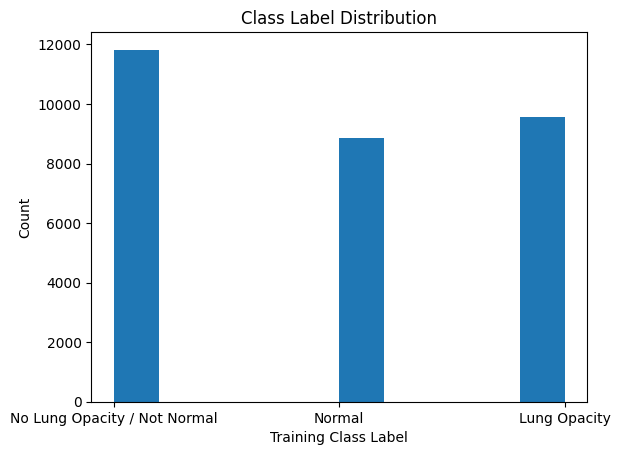

In [ ]:
plt.hist(train_data_classfier["class"].values)
plt.title("Class Label Distribution")
plt.xlabel("Training Class Label")
plt.ylabel("Count")

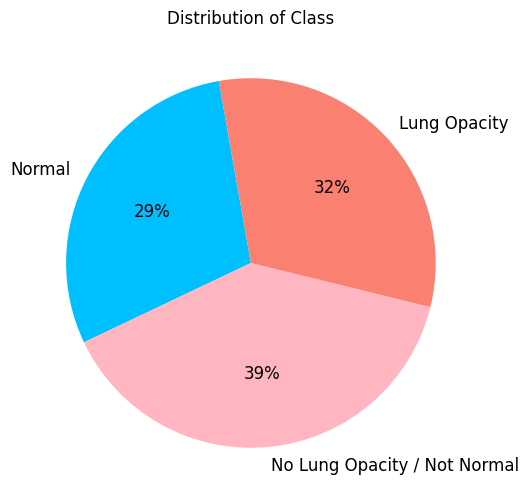

In [ ]:
fig = plt.figure(figsize=(10,6))
g = (train_data_classfier['class'].value_counts().sort_index(ascending=False).plot(kind='pie', autopct='%.0f%%', colors=['deepskyblue', 'lightpink', 'salmon'], startangle=100, title='Distribution of Class', fontsize=12).set_ylabel(''))

<span style="color:#F10086;font-size:24Px;"><b><u>2. Checking the number of bounding boxes for each unique patient.</u></b></span>

In [ ]:
print('Grouping by patient IDs and checking the number of bounding boxes for each unique patient ID\n')

boundingboxes = train_dataset.groupby('patientId').size().to_frame('number_of_boxes').reset_index()
train_dataset = train_dataset.merge(boundingboxes, on='patientId', how='left')
print('Number of unique patient IDs in the dataset: {}'.format(len(boundingboxes)))
print('Number of patient IDs per bounding boxes in the dataset')
(boundingboxes.groupby('number_of_boxes').size().to_frame('number_of_patientIDs_per_boxes').reset_index().set_index('number_of_boxes').sort_values(by='number_of_boxes'))

Grouping by patient IDs and checking the number of bounding boxes for each unique patient ID

Number of unique patient IDs in the dataset: 26684
Number of patient IDs per bounding boxes in the dataset


,number_of_patientIDs_per_boxes
number_of_boxes,
1,23286
2,3266
3,119
4,13


In [ ]:
new_train_dataset = pd.concat([train_dataset, train_data_classfier['class']], axis = 1)
new_train_dataset.head(5)

,patientId,width,height,Target,class
0,0004cfab-14fd-4e49-80ba-63a80b6bddd6,NaN,NaN,0,No Lung Opacity / Not Normal
1,00313ee0-9eaa-42f4-b0ab-c148ed3241cd,NaN,NaN,0,No Lung Opacity / Not Normal
2,00322d4d-1c29-4943-afc9-b6754be640eb,NaN,NaN,0,No Lung Opacity / Not Normal
3,003d8fa0-6bf1-40ed-b54c-ac657f8495c5,NaN,NaN,0,Normal
4,00436515-870c-4b36-a041-de91049b9ab4,213.0,379.0,1,Lung Opacity


In [ ]:
print('Shape of the dataset after number of boxes column: {}'.format(new_train_dataset.shape))

Shape of the dataset after number of boxes column: (30227, 5)



<span style="color:#F10086;font-size:24Px;">**<u><b>Observation:</b></u></span>**<br/>

<span style="color:#F10086;font-size:18Px;">**1. Training data contains patientIds and bounding boxes as x, y, width and height.</span>**<br/>
<span style="color:#F10086;font-size:18Px;">**2. There are multiple records for patients. Number of duplicates in patientID = 3543.</span>**<br/>
<span style="color:#F10086;font-size:18Px;">**3. There is also a binary target column i.e. Target indicating presence or absence of pneumonia.</span>**<br/>
<span style="color:#F10086;font-size:18Px;">**4. Class label contains: No Lung Opacity/Not Normal, Normal and Lung Opacity.</span>**<br/>
<span style="color:#F10086;font-size:18Px;">**5. Chest examination with Target=1, presence of pneumonia are associated with the Lung Opacity class.</span>**<br/>
<span style="color:#F10086;font-size:18Px;">**6. Chest examination with Target=0, absence of pneumonia are associated with either as Normal or No Lung Opacity/Not Normal class.</span>**<br/>
<span style="color:#F10086;font-size:18Px;">**7. About 23286 patientIds has 1 bounding boxes, while 13 patients have 4 bounding boxes.</span>**

<span style="color:#F10086;font-size:24Px;"><b><u>3. Plotting number of class within target value.</u></b></span>

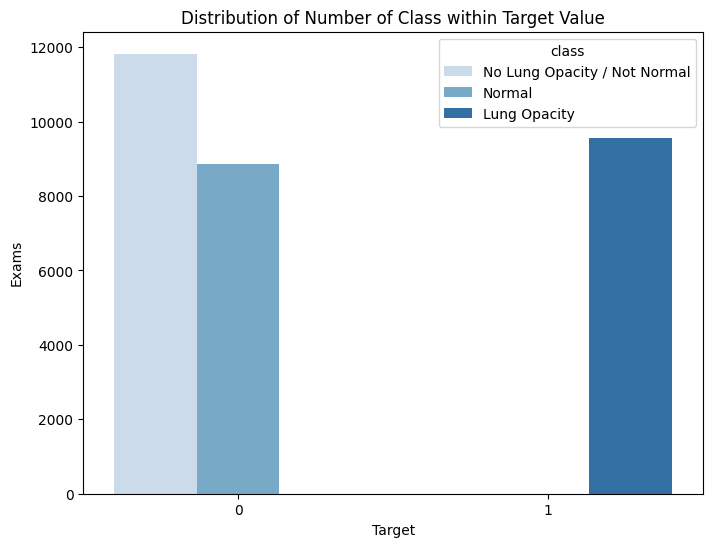

In [ ]:
ig, ax = plt.subplots(nrows=1,figsize=(8,6))

tmp = new_train_dataset.groupby('Target')['class'].value_counts()
df = pd.DataFrame(data={'Exams':tmp.values},index=tmp.index).reset_index()

sns.barplot(ax=ax, x='Target', y='Exams', hue='class', data=df, palette="Blues")
plt.title("Distribution of Number of Class within Target Value")
plt.show()

<span style="color:#F10086;font-size:18Px;"><b>Target 1</b> represents the <b>lung opicity</b> class.</span><br/>
<span style="color:#F10086;font-size:18Px;"><b>Target 0</b> represents the <b>No Lung Opacity/Not Normal</b> and <b>Normal</b> class.</span>

<span style="color:#F10086;font-size:24Px;">**<u><b>4. Feature extraction from the dicom image files:</b></u></span>**

<span style="color:#F10086;font-size:18Px;">**1. Exploring modality.</span>**<br/>
<span style="color:#F10086;font-size:18Px;">**2. Exploring Body Part Examined.</span>**<br/>
<span style="color:#F10086;font-size:18Px;">**3. Exploring different view positions in the dataset.</span>**<br/>
<span style="color:#F10086;font-size:18Px;">**4. To understand distribution of age for the presence and absence of lung opacity/Pneumonia.</span>**<br/>
<span style="color:#F10086;font-size:18Px;">**5. To understand distribution of gender for the presence and absence of lung opacity/Pneumonia.</span>**

In [ ]:
TRAIN_IMAGES = TRAIN_IMG_DIR
sample_patient_id = new_train_dataset['patientId'][0]
dcm_file = TRAIN_IMAGES + '{}.dcm'.format(sample_patient_id)
dcm_data = pydicom.dcmread(dcm_file)

print(dcm_data)
print("Accessing data")
print(dcm_data.pixel_array)
print("Array shape data")
print(dcm_data.pixel_array.shape)

Dataset.file_meta -------------------------------
(0002,0000) File Meta Information Group Length  UL: 202
(0002,0001) File Meta Information Version       OB: b'\x00\x01'
(0002,0002) Media Storage SOP Class UID         UI: Secondary Capture Image Storage
(0002,0003) Media Storage SOP Instance UID      UI: 1.2.276.0.7230010.3.1.4.8323329.28530.1517874485.775526
(0002,0010) Transfer Syntax UID                 UI: JPEG Baseline (Process 1)
(0002,0012) Implementation Class UID            UI: 1.2.276.0.7230010.3.0.3.6.0
(0002,0013) Implementation Version Name         SH: 'OFFIS_DCMTK_360'
-------------------------------------------------
(0008,0005) Specific Character Set              CS: 'ISO_IR 100'
(0008,0016) SOP Class UID                       UI: Secondary Capture Image Storage
(0008,0018) SOP Instance UID                    UI: 1.2.276.0.7230010.3.1.4.8323329.28530.1517874485.775526
(0008,0020) Study Date                          DA: '19010101'
(0008,0030) Study Time                  

<span style="color:#F10086;font-size:18Px;">1. From the above sample, After reading the dicom file, which contains information that can be used for further analysis such as Patient's Sex, Age, Body Part Examined - **Chest**, View Position - **Anterior-Posterior (AP) or Posterior-Anterior (PA)** and Modality - **Computed Radiography (CR)**.</span><br/>
<span style="color:#F10086;font-size:18Px;">**2. Size of this image is 1024 x 1024 (Rows x Columns).</span>**

In [ ]:
from tqdm import tqdm, notebook

vars = ['Modality', 'PatientAge', 'PatientSex', 'BodyPartExamined', 'ViewPosition']
data_path = TRAIN_IMAGES
def process_dicom_data(data_df, TRAIN_IMAGES):
    for var in vars:
        data_df[var] = None
    image_names = os.listdir(TRAIN_IMAGES)
    for i, img_name in tqdm(enumerate(image_names)):
        imagePath = os.path.join(TRAIN_IMAGES,img_name)
        data_row_img_data = pydicom.dcmread(imagePath)
        idx = (data_df['patientId']==data_row_img_data.PatientID)
        data_df.loc[idx,'Modality'] = data_row_img_data.Modality
        data_df.loc[idx,'PatientAge'] = pd.to_numeric(data_row_img_data.PatientAge)
        data_df.loc[idx,'PatientSex'] = data_row_img_data.PatientSex
        data_df.loc[idx,'BodyPartExamined'] = data_row_img_data.BodyPartExamined
        data_df.loc[idx,'ViewPosition'] = data_row_img_data.ViewPosition

In [ ]:
process_dicom_data(new_train_dataset,TRAIN_IMAGES)

26707it [18:56, 23.50it/s]


<span style="color:#F10086;font-size:18Px;">**4.1. Exploring modality.</span>**

In [ ]:
print("Modality: train:",new_train_dataset['Modality'].unique())

Modality: train: ['CR']


<span style="color:#F10086;font-size:18Px;">**4.2. Exploring Body Part Examined.</span>**

In [ ]:
print("Body Part Examined: train:",new_train_dataset['BodyPartExamined'].unique())

Body Part Examined: train: ['CHEST']


<span style="color:#F10086;font-size:18Px;">**4.3. Exploring different view positions in the dataset.</span>**

In [ ]:
print("View Position: train:",new_train_dataset['ViewPosition'].unique())

View Position: train: ['PA' 'AP']


Distribution of `ViewPosition


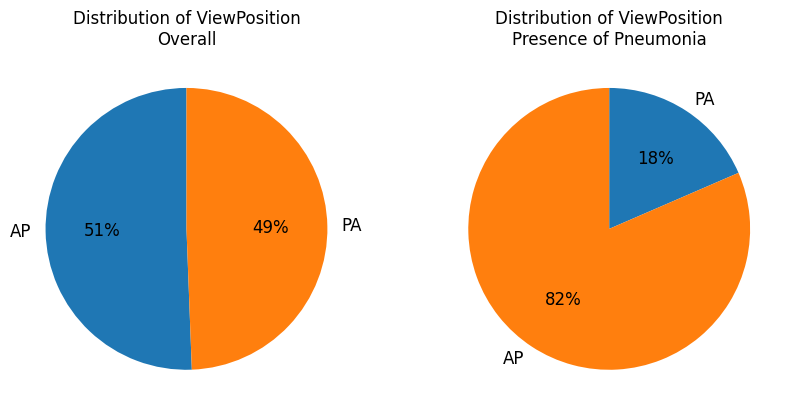

In [ ]:
print('Distribution of `ViewPosition')
fig = plt.figure(figsize = (10, 6))
ax = fig.add_subplot(121)
g = (new_train_dataset['ViewPosition'].value_counts().plot(kind='pie', autopct='%.0f%%',startangle=90,title='Distribution of ViewPosition\nOverall', fontsize=12).set_ylabel(''))
ax = fig.add_subplot(122)
g = (new_train_dataset.loc[new_train_dataset['Target']==1, 'ViewPosition'].value_counts().sort_index(ascending=False).plot(kind='pie', autopct='%.0f%%',startangle=90, counterclock=False, title='Distribution of ViewPosition\nPresence of Pneumonia',fontsize=12).set_ylabel(''))

<span style="color:#F10086;font-size:18Px;">**4.4. To understand distribution of age for the presence and absence of lung opacity/Pneumonia.</span>**

Text(0.5, 1.0, 'Distribution of PatientAge\nPresence of Pneumonia')

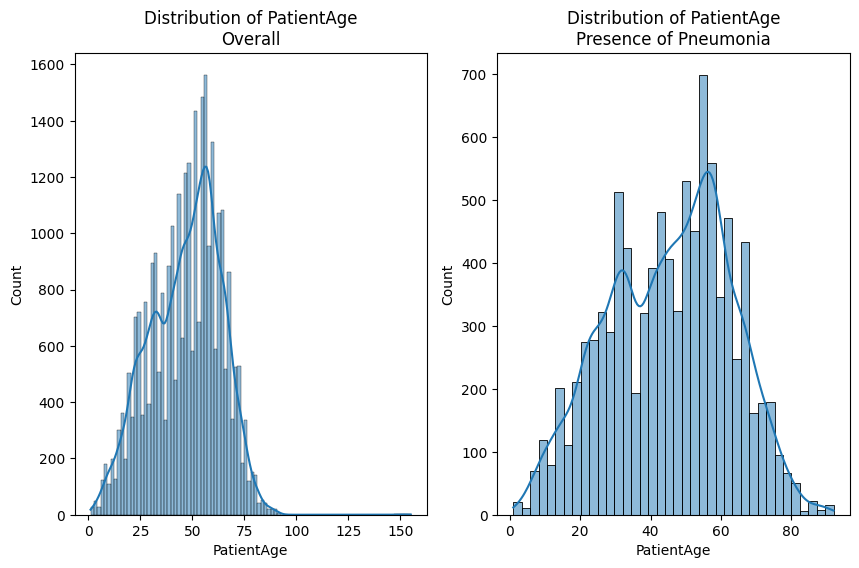

In [ ]:
fig, (ax1,ax2) =plt.subplots(1,2,figsize=(10,6))

sns.histplot(new_train_dataset['PatientAge'], kde=True, ax=ax1)
ax1.set_title('Distribution of PatientAge\nOverall')

sns.histplot(new_train_dataset.loc[new_train_dataset['Target']==1, 'PatientAge'], kde=True, ax=ax2)
ax2.set_title('Distribution of PatientAge\nPresence of Pneumonia')

<span style="color:#F10086;font-size:18Px;"><b>4.4.1 Outlier - Detection and Removing.</b></span>

Minimum `PatientAge` in the training dataset: 1
Maximum `PatientAge` in the training dataset: 155
25th Percentile of `PatientAge` in the training dataset: 34.0
50th Percentile of `PatientAge` in the training dataset: 49.0
75th Percentile of `PatientAge` in the training dataset: 59.0
`PatientAge` in upper whisker for box plot: 84.0



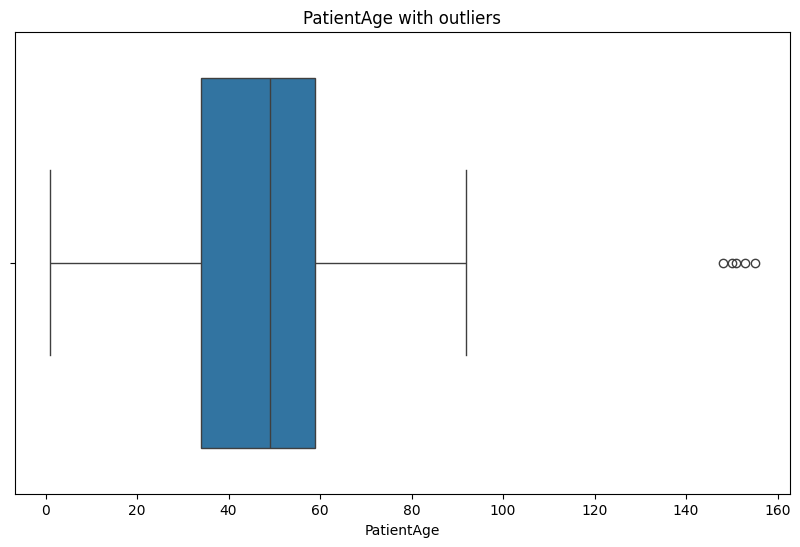

In [ ]:
print('Minimum `PatientAge` in the training dataset: {}'.format(new_train_dataset['PatientAge'].min()))
print('Maximum `PatientAge` in the training dataset: {}'.format(new_train_dataset['PatientAge'].max()))
print('25th Percentile of `PatientAge` in the training dataset: {}'.format(new_train_dataset['PatientAge'].quantile(0.25)))
print('50th Percentile of `PatientAge` in the training dataset: {}'.format(new_train_dataset['PatientAge'].quantile(0.50)))
print('75th Percentile of `PatientAge` in the training dataset: {}'.format(new_train_dataset['PatientAge'].quantile(0.75)))
print('`PatientAge` in upper whisker for box plot: {}'.format(new_train_dataset['PatientAge'].quantile(0.75) + (new_train_dataset['PatientAge'].quantile(0.75) - new_train_dataset['PatientAge'].quantile(0.25))))
print()
fig = plt.figure(figsize=(10, 6))
ax = sns.boxplot(data=new_train_dataset['PatientAge'], orient='h').set_title('PatientAge with outliers')

Setting the upper threshold as 100 for age and removing outliers


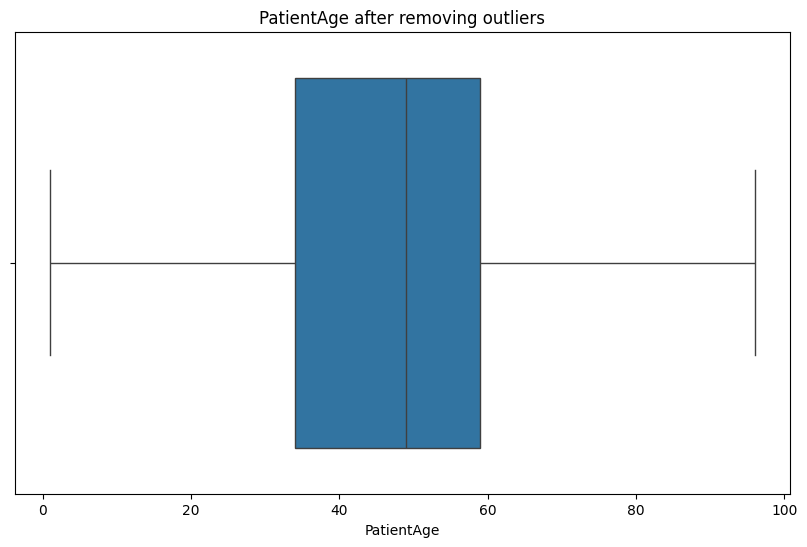

In [ ]:
print('Setting the upper threshold as 100 for age and removing outliers')
new_train_dataset['PatientAge'] = new_train_dataset['PatientAge'].clip(new_train_dataset['PatientAge'].min(), 96)

fig = plt.figure(figsize=(10, 6))
ax = sns.boxplot(data=new_train_dataset['PatientAge'], orient='h').set_title('PatientAge after removing outliers')


Text(0.5, 1.0, 'Distribution of PatientAge\nPresence of Pneumonia\nafter removing outliers')

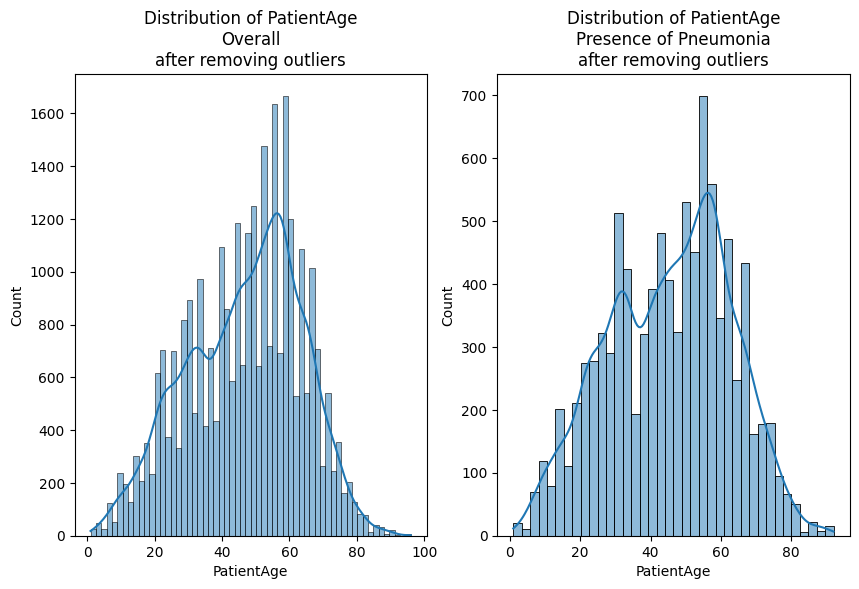

In [ ]:
fig, (ax1,ax2) =plt.subplots(1,2,figsize=(10,6))

sns.histplot(new_train_dataset['PatientAge'], kde=True, ax=ax1)
ax1.set_title('Distribution of PatientAge\nOverall\nafter removing outliers')

sns.histplot(new_train_dataset.loc[new_train_dataset['Target']==1, 'PatientAge'], kde=True, ax=ax2)
ax2.set_title('Distribution of PatientAge\nPresence of Pneumonia\nafter removing outliers')

In [ ]:
print('Creating Age Binning')
new_train_dataset['AgeBins']=pd.cut(new_train_dataset['PatientAge'], bins=5, precision=0, labels=['<=20', '<=40', '<=60', '<=80', '<=100'])
new_train_dataset['AgeBins'].value_counts()

Creating Age Binning


,count
AgeBins,
<=60,12436
<=40,7613
<=80,7477
<=20,2203
<=100,498


,Counts of Age Bins - Overall,Counts of Age Bins - Target=1
AgeBins,,
<=20,2203,821
<=40,7613,2613
<=60,12436,3841
<=80,7477,2110
<=100,498,170


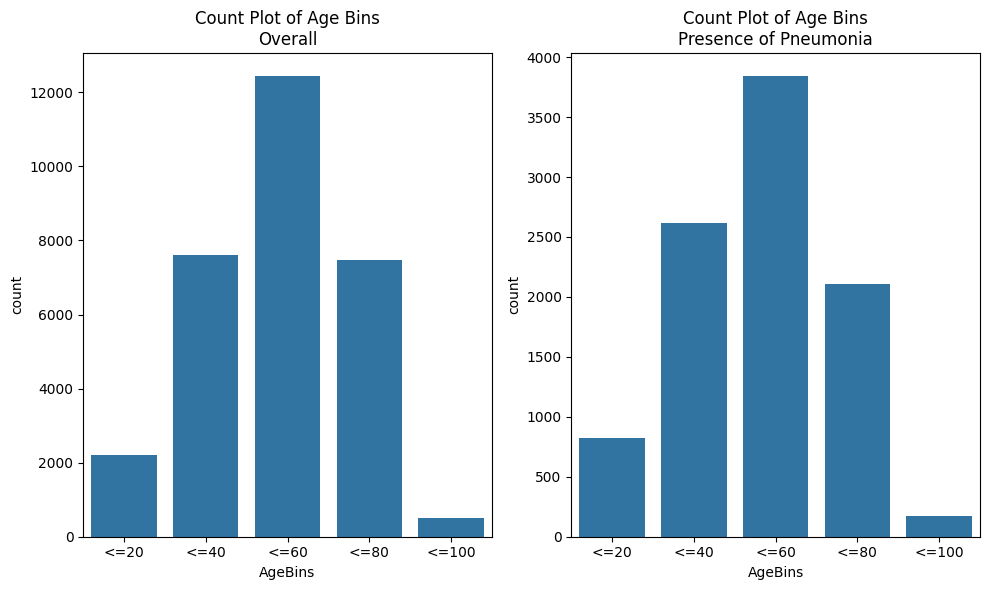

In [ ]:
display(pd.concat([new_train_dataset['AgeBins'].value_counts().sort_index().rename('Counts of Age Bins - Overall'), new_train_dataset.loc[new_train_dataset['Target'] == 1, 'AgeBins'].value_counts().sort_index().rename('Counts of Age Bins - Target=1')], axis=1))

f, (ax1, ax2) = plt.subplots(1, 2, figsize = (10, 6))
g = sns.countplot(x=new_train_dataset['AgeBins'], ax=ax1).set_title('Count Plot of Age Bins\nOverall')
g = sns.countplot(x=new_train_dataset.loc[new_train_dataset['Target'] == 1, 'AgeBins'], ax=ax2).set_title('Count Plot of Age Bins\nPresence of Pneumonia')
plt.tight_layout()

<span style="color:#F10086;font-size:18Px;">**4.5. To understand distribution of gender for the presence and absence of lung opacity/Pneumonia.</span>**

Distribution of age for patients with Pneumonia Evidence, by Gender


,"% Gender, Overall","% Gender, Target=1"
PatientSex,,
F,0.43,0.42
M,0.57,0.58


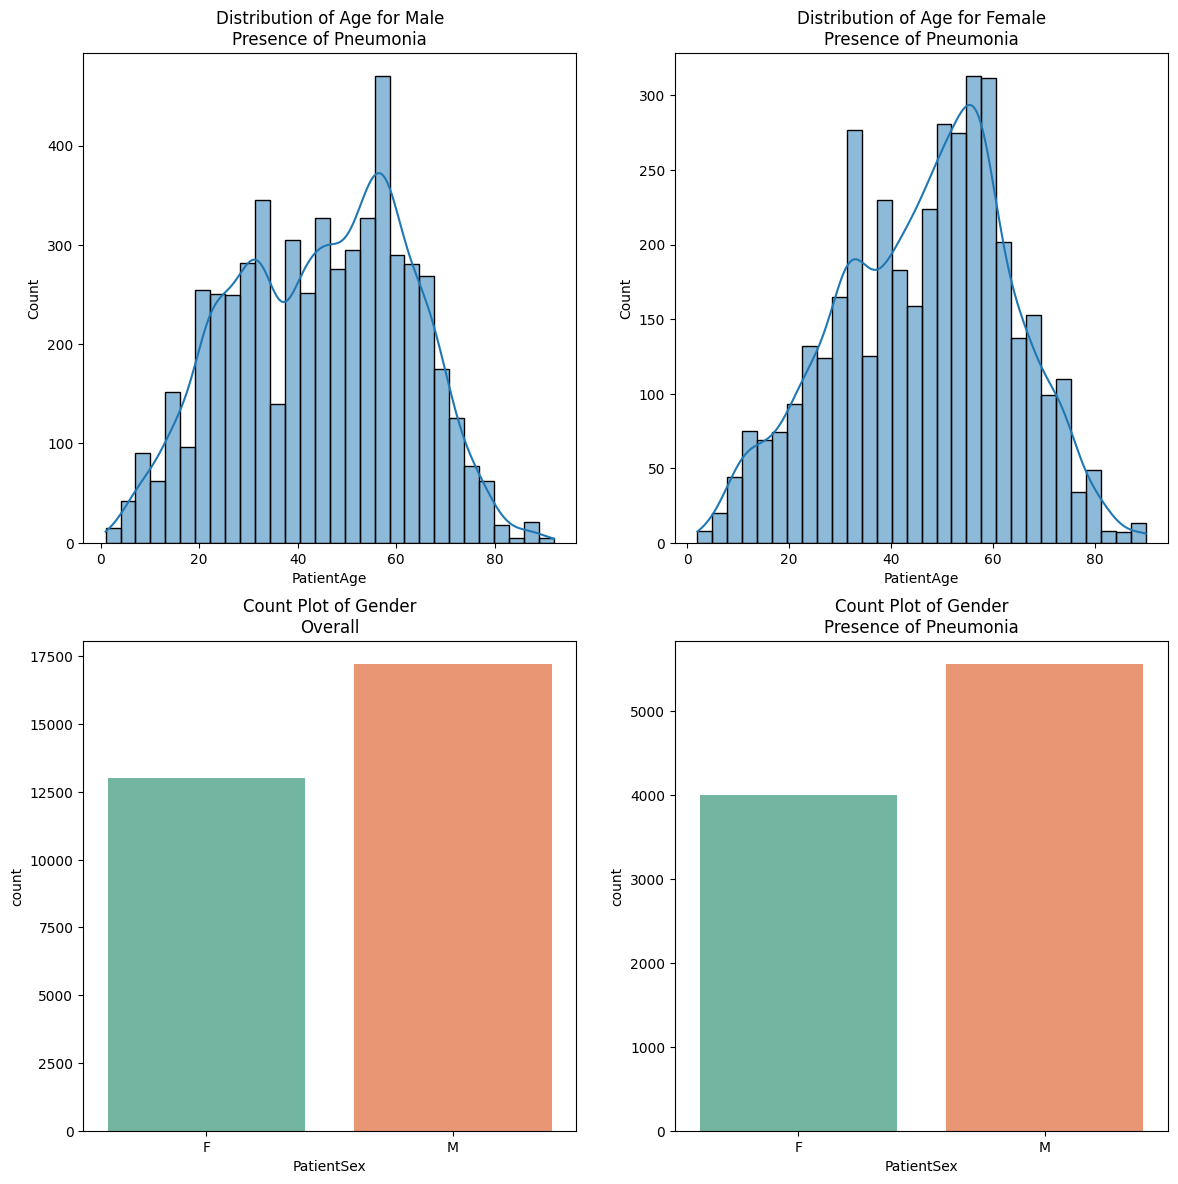

In [ ]:
print('Distribution of age for patients with Pneumonia Evidence, by Gender')
display(pd.concat([new_train_dataset['PatientSex'].value_counts(normalize=True).round(2).sort_values().rename('% Gender, Overall'), new_train_dataset.loc[(new_train_dataset['Target'] == 1), 'PatientSex'].value_counts(normalize=True).round(2).sort_index().rename('% Gender, Target=1')], axis=1))

f, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize = (14, 14))
g = sns.histplot(new_train_dataset.loc[(new_train_dataset['Target'] == 1) & (new_train_dataset['PatientSex'] == 'M'), 'PatientAge'], kde=True, ax=ax1)
ax1.set_title('Distribution of Age for Male\nPresence of Pneumonia')

g = sns.histplot(new_train_dataset.loc[(new_train_dataset['Target'] == 1) & (new_train_dataset['PatientSex'] == 'F'), 'PatientAge'], kde=True, ax = ax2)
ax2.set_title('Distribution of Age for Female\nPresence of Pneumonia')

g = sns.countplot(x=new_train_dataset['PatientSex'], ax=ax3, palette='Set2')
ax3.set_title('Count Plot of Gender\nOverall')

g = sns.countplot(x=new_train_dataset.loc[(new_train_dataset['Target'] == 1), 'PatientSex'], ax=ax4, palette='Set2')
ax4.set_title('Count Plot of Gender\nPresence of Pneumonia')
fig.tight_layout()

 <span style="color:#F10086;font-size:24Px;"><b><u>Step-3: Reading Images.</u></b></span>

In [ ]:
#DATA_DIR = '/content/drive/My Drive/ColabNotebooks/CAPSTONE/'  # local path
#TRAIN_IMG_DIR = os.path.join(DATA_DIR, 'stage_2_train_images/')
#TEST_IMG_DIR = os.path.join(DATA_DIR, 'stage_2_test_images/')

sampleImage0 = os.path.join(TRAIN_IMG_DIR,'001031d9-f904-4a23-b3e5-2c088acd19c6.dcm')
img_arr = pydicom.dcmread(sampleImage0).pixel_array
print("Image shape :",img_arr.shape)

Image shape : (1024, 1024)


Text(0, 0.5, 'Pixel Count')

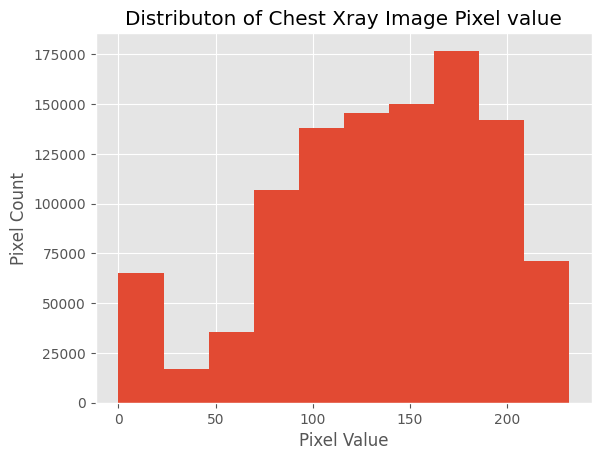

In [ ]:
plt.style.use('ggplot')
plt.hist(img_arr.flatten())
plt.title("Distributon of Chest Xray Image Pixel value")
plt.xlabel("Pixel Value")
plt.ylabel("Pixel Count")

In [ ]:
normalized = img_arr/img_arr.max()

Text(0, 0.5, 'Pixel Count')

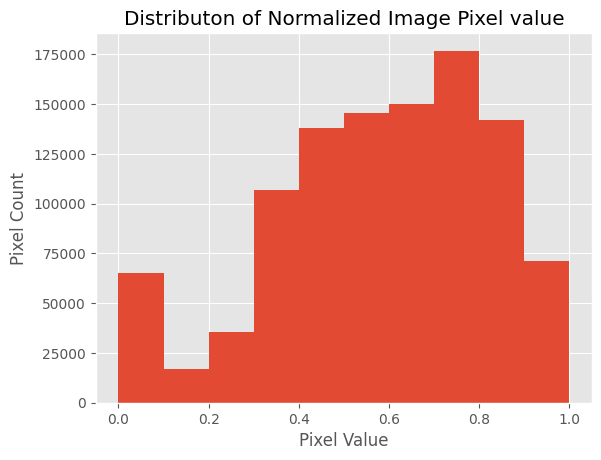

In [ ]:
plt.style.use('ggplot')
plt.hist(normalized.flatten())
plt.title("Distributon of Normalized Image Pixel value")
plt.xlabel("Pixel Value")
plt.ylabel("Pixel Count")

In [ ]:
# read the image and preprocess the image

def read_Image(path):
    img_arr = pydicom.dcmread(path).pixel_array
    normalized = img_arr/img_arr.max()
    return np.array(normalized)

In [ ]:
new_train_dataset["patientId"].iloc[10]

'008c19e8-a820-403a-930a-bc74a4053664'

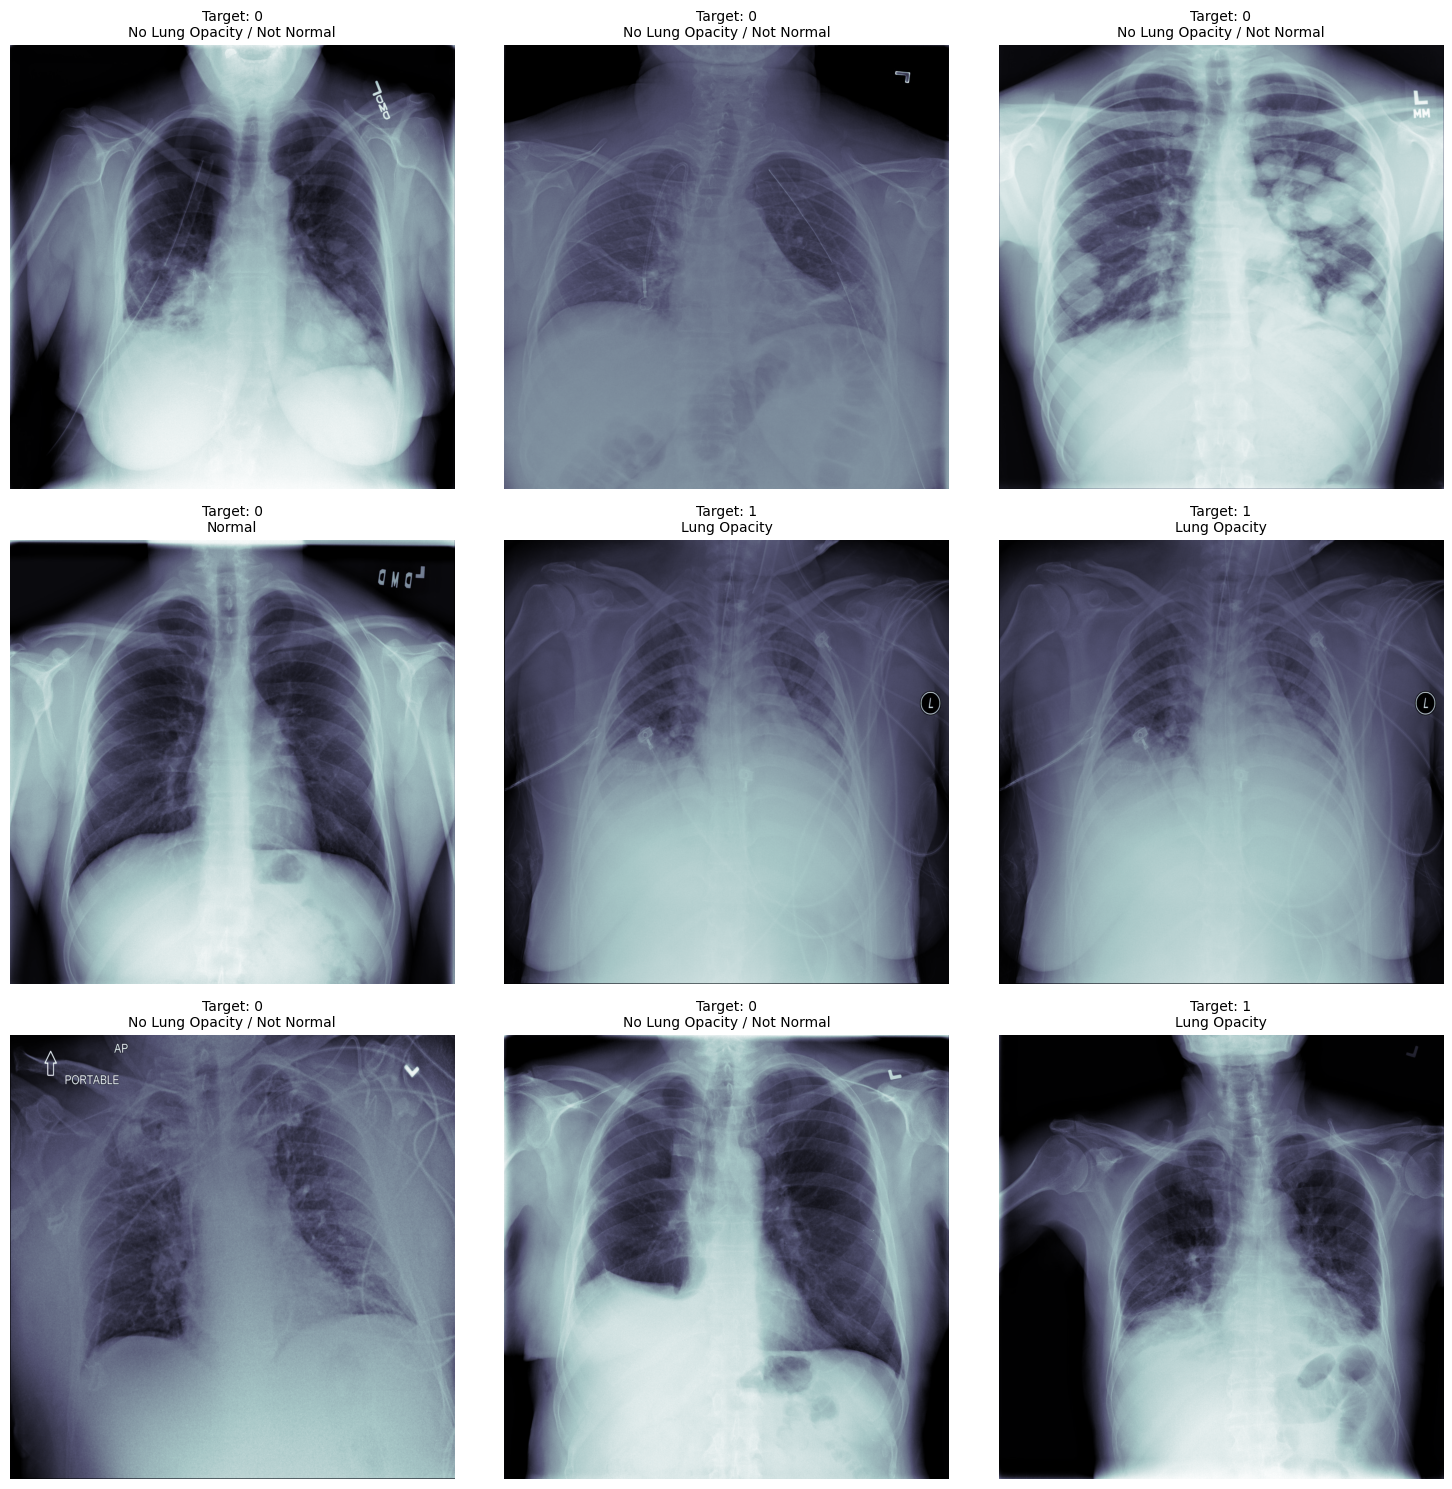

In [ ]:
import pydicom
import matplotlib.pyplot as plt

def plot_first_9(df, img_dir):
    plt.figure(figsize=(15, 15))

    # Grab the first 9 rows
    subset = df.head(9)

    for i, (idx, row) in enumerate(subset.iterrows()):
        patient_id = row['patientId']
        img_path = f"{img_dir}/{patient_id}.dcm"

        try:
            # Read and extract pixel data
            ds = pydicom.dcmread(img_path)
            img_data = ds.pixel_array

            # Create subplot
            plt.subplot(3, 3, i + 1)
            plt.imshow(img_data, cmap='bone')

            # Title with Target and Class
            plt.title(f"Target: {row['Target']}\n{row['class']}", fontsize=10)
            plt.axis('off')

        except FileNotFoundError:
            plt.subplot(3, 3, i + 1)
            plt.text(0.5, 0.5, f"File Not Found:\n{patient_id}", ha='center')
            plt.axis('off')

    plt.tight_layout()
    plt.show()

# Execute the function
plot_first_9(new_train_dataset, TRAIN_IMG_DIR)

In [ ]:
# Execute the function
plot_first_9(new_train_dataset, TRAIN_IMG_DIR)

 <span style="color:#F10086;font-size:24Px;"><b><u>3.1: Display images with bounding box.</u></b></span>

In [ ]:
def Displayimages_with_bounding_box(data):
    path = TRAIN_IMG_DIR
    img_data = list(data.T.to_dict().values())
    f, ax = plt.subplots(3,3, figsize=(16,18))
    for i,data_row in enumerate(img_data):
        patientImage = data_row['patientId']+'.dcm'
        data_row_img_data = read_Image(path+patientImage)

        data_row_img = pydicom.dcmread(path+patientImage)
        ax[i//3, i%3].imshow(data_row_img.pixel_array, cmap=plt.cm.bone)
        ax[i//3, i%3].axis('off')
        ax[i//3, i%3].set_title('ID: {} Target: {}\nClass: {}'.format(
                data_row['patientId'],data_row['Target'], data_row['class']))
        rows = new_train_dataset[new_train_dataset['patientId']==data_row['patientId']]
        box_data = list(rows.T.to_dict().values())
        for j, row in enumerate(box_data):
            ax[i//3, i%3].add_patch(Rectangle(xy=(row['x'], row['y']),
                        width=row['width'],height=row['height'],
                        color="red",alpha = 0.2))
    plt.show()

In [ ]:
import matplotlib.pyplot as plt
import pydicom
from matplotlib.patches import Rectangle
import numpy as np

def Displayimages_with_bounding_box(data):
    path = TRAIN_IMG_DIR
    # Get the first 9 unique patients to fill the 3x3 grid perfectly
    unique_patients = data['patientId'].unique()[:9]

    # Create the figure and subplots
    fig, axes = plt.subplots(3, 3, figsize=(18, 20))
    axes = axes.flatten() # <--- THIS FIXES THE TYPE ERROR (makes axes a 1D list)

    for i, p_id in enumerate(unique_patients):
        # 1. Load Image
        patient_path = f"{path}{p_id}.dcm"
        dcm_data = pydicom.dcmread(patient_path)
        img = dcm_data.pixel_array

        # 2. Get all rows for this patient (could be multiple boxes)
        patient_rows = data[data['patientId'] == p_id]
        first_row = patient_rows.iloc[0] # To get class/target for title

        # 3. Plot Image
        axes[i].imshow(img, cmap=plt.cm.bone)
        axes[i].set_title(f"ID: {p_id[:8]}...\nTarget: {first_row['Target']} | {first_row['class']}")
        axes[i].axis('off')

        # 4. Draw all bounding boxes for this patient
        for _, row in patient_rows.iterrows():
            # Check if coordinates exist and are not NaN
            if row['Target'] == 1 and not np.isnan(row['x']):
                rect = Rectangle(
                    (row['x'], row['y']), row['width'], row['height'],
                    linewidth=2, edgecolor='red', facecolor='none'
                )
                axes[i].add_patch(rect)

    plt.tight_layout()
    plt.show()



In [ ]:

print(new_train_dataset.info)


<bound method DataFrame.info of                                   patientId  width  height  Target  \
0      0004cfab-14fd-4e49-80ba-63a80b6bddd6    NaN     NaN       0   
1      00313ee0-9eaa-42f4-b0ab-c148ed3241cd    NaN     NaN       0   
2      00322d4d-1c29-4943-afc9-b6754be640eb    NaN     NaN       0   
3      003d8fa0-6bf1-40ed-b54c-ac657f8495c5    NaN     NaN       0   
4      00436515-870c-4b36-a041-de91049b9ab4  213.0   379.0       1   
...                                     ...    ...     ...     ...   
30222  c1ec14ff-f6d7-4b38-b0cb-fe07041cbdc8  228.0   379.0       1   
30223  c1edf42b-5958-47ff-a1e7-4f23d99583ba    NaN     NaN       0   
30224  c1f6b555-2eb1-4231-98f6-50a963976431    NaN     NaN       0   
30225  c1f7889a-9ea9-4acb-b64c-b737c929599a  261.0   345.0       1   
30226  c1f7889a-9ea9-4acb-b64c-b737c929599a  201.0   356.0       1   

                              class  
0      No Lung Opacity / Not Normal  
1      No Lung Opacity / Not Normal  
2      No Lun

##### <span style="color:#3E00FF;font-size:24Px;">Step 6: Design, train and test basic CNN models for classification.</span>
>> ##### <span style="color:#F10086;font-size:24Px;">Step 4: Design, train and test basic CNN models for classification.</span>


In [ ]:
IMAGE_WIDTH = IMAGE_HEIGHT = 256
CHANNEL = 3

In [ ]:
import tensorflow as tf

class simpleDensenet():
    def __init__(self,epochs,batch_size,lr=0.001):
        self.epochs = epochs
        self.batch_size = batch_size
        self.lr = lr
        self.dense_depth= 2
        self.start_neurons = 16

    def convolutionBlock(self,x, filters, size, strides=(1,1), padding='same'):
        x = tf.keras.layers.Conv2D(filters, size, strides=strides, padding=padding)(x)
        x = tf.keras.layers.BatchNormalization()(x)
        x = tf.keras.layers.Activation('elu')(x)
        return x

    def denseBlock(self,blockInput, num_filters=16, batch_activate = False):
        list_Conv = [blockInput]
        pas=self.convolutionBlock(blockInput, num_filters,size=(3,3),strides=(1,1))

        for i in range(2 , self.dense_depth+1):
            list_Conv.append(pas)
            out =  tf.keras.layers.Concatenate(axis = 3)(list_Conv) # conctenated out put
            pas = self.convolutionBlock(out, num_filters,size=(3,3),strides=(1,1))

            list_Conv.append(pas)

        out = tf.keras.layers.Concatenate(axis =3)(list_Conv)
        feature = self.convolutionBlock(out, num_filters,size=(3,3),strides=(1,1))

        return feature


    def build(self,inputShape = (IMAGE_WIDTH, IMAGE_HEIGHT,CHANNEL),number_classes=None):

        input_layer = tf.keras.layers.Input(inputShape)
        conv1 = self.convolutionBlock(input_layer,self.start_neurons,(3,3))
        dense0 = self.denseBlock(conv1,self.start_neurons)
        mxpool1 = tf.keras.layers.MaxPooling2D((2, 2))(dense0)

        conv2 = self.convolutionBlock(mxpool1,self.start_neurons*2,(3,3))
        dense1 = self.denseBlock(conv2,self.start_neurons*2)
        mxpool2 = tf.keras.layers.MaxPooling2D((2, 2))(dense1)

        conv3 = self.convolutionBlock(mxpool2,self.start_neurons*4,(3,3))
        dense3 = self.denseBlock(conv3,self.start_neurons*4)
        mxpool3 = tf.keras.layers.MaxPooling2D((2, 2))(dense3)

        conv4= self.convolutionBlock(mxpool3,self.start_neurons*4,(3,3))
        dense4 = self.denseBlock(conv4,self.start_neurons*4)
        mxpool4 = tf.keras.layers.MaxPooling2D((2, 2))(dense4)

        conv5= self.convolutionBlock(mxpool4,self.start_neurons*6,(3,3))
        dense5 = self.denseBlock(conv5,self.start_neurons*6)

        GA =tf.keras.layers.GlobalAveragePooling2D()(dense5)
        GA= tf.keras.layers.Dropout(0.1)(GA)

        fc = tf.keras.layers.Dense(number_classes,activation="softmax")(GA) #class_types= 10

        self.model = tf.keras.Model(input_layer, fc)
        self.model.compile(loss="sparse_categorical_crossentropy", optimizer=tf.keras.optimizers.Adam(self.lr),metrics=["acc"])

        print("model input : ",self.model.input)
        print("model output : ",self.model.output)

        return self.model

    def run(self,x_train,x_test):
        checkpoint_filepath = "./denseNet_classifier.weights.h5"
        checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
        checkpoint_filepath,
        monitor="val_loss",
        save_best_only=True,
        save_weights_only=True,
        mode = 'min',
        verbose=1)
        reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', mode = 'min',
                              factor=0.1, patience=5, min_lr=0.00001, verbose=1)
        history = self.model.fit(
              generate_data(x_train,self.batch_size,True),
              validation_data=generate_data(x_test,self.batch_size),
              epochs=self.epochs,
              steps_per_epoch=len(x_train)//self.batch_size,
              validation_steps=len(x_test)//self.batch_size,
            verbose=1,
            callbacks=[checkpoint_callback,reduce_lr]
          )

        return self.model,history

In [ ]:
sample_patient_id = train_labels_df['patientId'][0]
dcm_file = TRAIN_IMG_DIR + '{}.dcm'.format(sample_patient_id)
dcm_data = dcm.dcmread(dcm_file)
print(dcm_data)

Dataset.file_meta -------------------------------
(0002,0000) File Meta Information Group Length  UL: 202
(0002,0001) File Meta Information Version       OB: b'\x00\x01'
(0002,0002) Media Storage SOP Class UID         UI: Secondary Capture Image Storage
(0002,0003) Media Storage SOP Instance UID      UI: 1.2.276.0.7230010.3.1.4.8323329.28530.1517874485.775526
(0002,0010) Transfer Syntax UID                 UI: JPEG Baseline (Process 1)
(0002,0012) Implementation Class UID            UI: 1.2.276.0.7230010.3.0.3.6.0
(0002,0013) Implementation Version Name         SH: 'OFFIS_DCMTK_360'
-------------------------------------------------
(0008,0005) Specific Character Set              CS: 'ISO_IR 100'
(0008,0016) SOP Class UID                       UI: Secondary Capture Image Storage
(0008,0018) SOP Instance UID                    UI: 1.2.276.0.7230010.3.1.4.8323329.28530.1517874485.775526
(0008,0020) Study Date                          DA: '19010101'
(0008,0030) Study Time                  

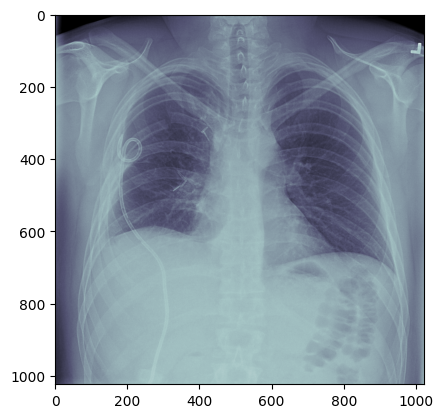

In [ ]:
from PIL import Image
import pydicom

training_image_path = TRAIN_IMG_DIR
sampleImage = "c3b05294-29be-46e4-8a51-96fd211e4ca5.dcm"

sample0 = pydicom.dcmread(training_image_path+sampleImage)
plt.imshow(sample0.pixel_array, cmap=plt.cm.bone)

In [ ]:
print("Original Image shape : " ,sample0)

Original Image shape :  Dataset.file_meta -------------------------------
(0002,0000) File Meta Information Group Length  UL: 200
(0002,0001) File Meta Information Version       OB: b'\x00\x01'
(0002,0002) Media Storage SOP Class UID         UI: Secondary Capture Image Storage
(0002,0003) Media Storage SOP Instance UID      UI: 1.2.276.0.7230010.3.1.4.8323329.3309.1517874301.407648
(0002,0010) Transfer Syntax UID                 UI: JPEG Baseline (Process 1)
(0002,0012) Implementation Class UID            UI: 1.2.276.0.7230010.3.0.3.6.0
(0002,0013) Implementation Version Name         SH: 'OFFIS_DCMTK_360'
-------------------------------------------------
(0008,0005) Specific Character Set              CS: 'ISO_IR 100'
(0008,0016) SOP Class UID                       UI: Secondary Capture Image Storage
(0008,0018) SOP Instance UID                    UI: 1.2.276.0.7230010.3.1.4.8323329.3309.1517874301.407648
(0008,0020) Study Date                          DA: '19010101'
(0008,0030) Study 

In [ ]:
print("Minimum Pixel Value : ", sample0.pixel_array.min(), "Maximum Pixel Value : ", sample0.pixel_array.max())

Minimum Pixel Value :  0 Maximum Pixel Value :  201


In [ ]:
from sklearn.model_selection import StratifiedKFold

trainingName=new_train_dataset["patientId"].values
trainingLabel=new_train_dataset["class"].values

skf = StratifiedKFold(n_splits=5)
skf.get_n_splits(trainingName,trainingLabel)

foldcount=1
for train_index, test_index in skf.split(trainingName,trainingLabel):

    X_train, X_test = new_train_dataset.iloc[train_index], new_train_dataset.iloc[test_index]

    X_train = X_train.sample(frac=1).reset_index(drop=True)

    X_test = X_test.sample(frac=1).reset_index(drop=True)


In [ ]:
print("Randoming Selecting dataset shape : ",X_test.shape)

Randoming Selecting dataset shape :  (6045, 5)


### **We have selected the 6045 images from the dataset. Split the dataset into three parts. The training size is 70% , validation data size is 15% and testing data size is 15%**

In [ ]:
from sklearn.model_selection import train_test_split

train_data, valid_temp, y_train, y_valid_temp = train_test_split(X_test["patientId"].values, X_test["class"].values, test_size=0.3, random_state=42,stratify=X_test["class"].values)

In [ ]:
valid_data, test_data, y_valid, y_test = train_test_split(valid_temp,y_valid_temp, test_size=0.5, random_state=12,stratify=y_valid_temp)

In [ ]:
print("training data shape : ",train_data.shape)
print("validation data shape : ",valid_data.shape)
print("testing data shape : ",test_data.shape)


training data shape :  (4231,)
validation data shape :  (907,)
testing data shape :  (907,)


In [ ]:
y_test[1:5]

array(['Normal', 'Normal', 'No Lung Opacity / Not Normal', 'Normal'],
      dtype=object)

### **Change the training and validation dataset for training.**

In [ ]:
train_new = pd.DataFrame(train_data)
train_new.columns = ["patientId"]
train_new["class"] =y_train

valid_new = pd.DataFrame(valid_data)
valid_new.columns = ["patientId"]
valid_new["class"] =y_valid

In [ ]:
train_new.head(5)

,patientId,class
0,fc8f23cb-b428-4f6f-b521-4211067f2901,No Lung Opacity / Not Normal
1,0124882b-de2f-4023-985f-debb74aa6ebb,Normal
2,e02463aa-2d6e-4d03-9d05-4cd0a8f7ebed,No Lung Opacity / Not Normal
3,103451bb-1f8c-4209-abce-0be7e9a6c8fb,Lung Opacity
4,fad6cec8-922a-4490-ab8c-57dd59e908c2,No Lung Opacity / Not Normal


In [ ]:
valid_new.head(5)

,patientId,class
0,f326a7ef-e7f7-43e0-8c9b-e8ab6033a567,Normal
1,cfca5fb2-0851-49fd-9dfb-f7b063992b0c,Lung Opacity
2,d58a922b-97c8-4ee8-ad84-1c4c6c883c86,Lung Opacity
3,f298a58f-b8a7-4805-80c1-1cf5025edefc,Normal
4,eb91a618-122c-4de4-88ab-eb534c3ef4c5,Lung Opacity


In [ ]:
print("class names : ",np.unique(train_new["class"].values))

class names :  ['Lung Opacity' 'No Lung Opacity / Not Normal' 'Normal']


In [ ]:
LabelDict ={'Lung Opacity':0,'No Lung Opacity / Not Normal':1,'Normal':2}

In [ ]:
LabelDict['No Lung Opacity / Not Normal']

1

In [ ]:
import cv2
IMG_WIDTH = IMG_HEIGHT = 256

#batch generator for training
def generate_data(train_set, batch_size,shuffle=False):

    i = 0
    train_ID=train_set["patientId"].values
    Y_label=train_set["class"].values

    while True:
        image_batch = np.zeros((batch_size,IMG_WIDTH,IMG_HEIGHT,1))
        y_batch= np.zeros((batch_size,1))

        for b in range(batch_size):
            if i == len(train_ID):
                i = 0
                #shuffle if u want to
                if shuffle:
                    train_set = train_set.sample(frac=1).reset_index(drop=True)
                    train_ID=train_set["patientId"].values
                    Y_label=train_set["class"].values

            sample = training_image_path+train_ID[i]

            #img=cv2.imread(sample)
            img = read_Image(sample+".dcm")
            image_resized = cv2.resize(img, (IMG_WIDTH,IMG_HEIGHT))
            image_batch[b,:,:,0] = image_resized
            y_batch[b] = LabelDict[Y_label[i]]

            #image_batch.append(image_resized)
            #y_batch.append([LabelDict[Y_label[i]]])
            i += 1
        image_batch=np.array(image_batch)
        y_batch= np.array(y_batch)
        yield  image_batch, y_batch

In [ ]:
model = simpleDensenet(epochs=1,batch_size=32,lr=0.0001)
temp_model = model.build(inputShape=(256,256,1),number_classes=3)
model_trained,history = model.run(train_new,valid_new)

model input :  <KerasTensor shape=(None, 256, 256, 1), dtype=float32, sparse=False, ragged=False, name=keras_tensor_234>
model output :  <KerasTensor shape=(None, 3), dtype=float32, sparse=False, ragged=False, name=keras_tensor_311>
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 15s/step - acc: 0.5107 - loss: 0.9489 
Epoch 1: val_loss improved from None to 1.54135, saving model to ./denseNet_classifier.weights.h5

Epoch 1: finished saving model to ./denseNet_classifier.weights.h5
132/132 ━━━━━━━━━━━━━━━━━━━━ 2488s 19s/step - acc: 0.5462 - loss: 0.9036 - val_acc: 0.3694 - val_loss: 1.5414 - learning_rate: 1.0000e-04


In [ ]:
temp_model = model.build(inputShape=(256,256,1),number_classes=3)

model input :  <KerasTensor shape=(None, 256, 256, 1), dtype=float32, sparse=False, ragged=False, name=keras_tensor_156>
model output :  <KerasTensor shape=(None, 3), dtype=float32, sparse=False, ragged=False, name=keras_tensor_233>


In [ ]:
model_trained,history = model.run(train_new,valid_new)

132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 480ms/step - acc: 0.5973 - loss: 0.8288
Epoch 1: val_loss improved from None to 1.46356, saving model to ./denseNet_classifier.weights.h5

Epoch 1: finished saving model to ./denseNet_classifier.weights.h5
132/132 ━━━━━━━━━━━━━━━━━━━━ 76s 577ms/step - acc: 0.6009 - loss: 0.8214 - val_acc: 0.3828 - val_loss: 1.4636 - learning_rate: 1.0000e-04


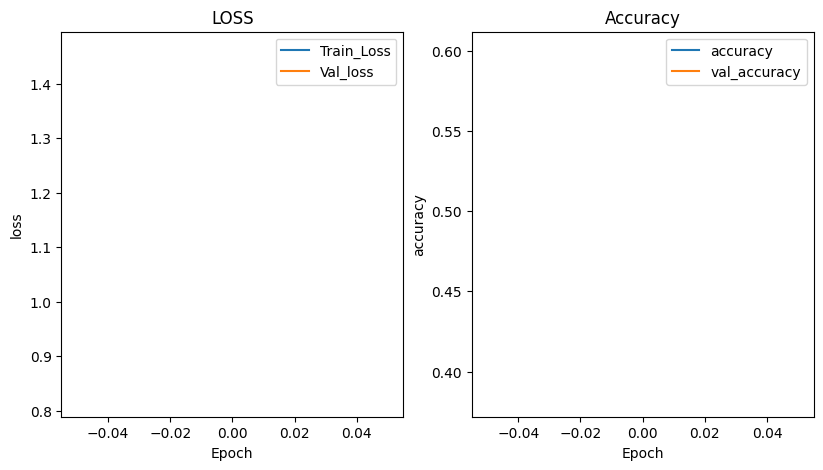

In [ ]:
plt.figure(figsize=(15,5))
plt.subplot(1,3,1)
plt.plot(range(history.epoch[-1]+1),history.history['loss'],label='Train_Loss')
plt.plot(range(history.epoch[-1]+1),history.history['val_loss'],label='Val_loss')
plt.title('LOSS'); plt.xlabel('Epoch'); plt.ylabel('loss');plt.legend();

plt.subplot(1,3,2)
plt.plot(range(history.epoch[-1]+1),history.history['acc'],label='accuracy')
plt.plot(range(history.epoch[-1]+1),history.history['val_acc'],label='val_accuracy')
plt.title('Accuracy'); plt.xlabel('Epoch'); plt.ylabel('accuracy');plt.legend();

In [ ]:
import itertools

def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):

    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, cm[i, j],
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

In [ ]:
from sklearn.metrics import confusion_matrix

#test_ID=X_train["patientId"].values
#Y_label=X_train["class"].values

y_test_new = []
y_pred_label = []
image_batch = np.zeros((1,IMG_WIDTH,IMG_HEIGHT,1))

for i in range(len(test_data)):
    sample = training_image_path+test_data[i]

    img = read_Image(sample+".dcm")

    image_resized = cv2.resize(img, (IMG_WIDTH,IMG_HEIGHT))
    image_batch[0,:,:,0] = image_resized
    y_test_new.append(LabelDict[y_test[i]])

    predicted = model_trained.predict(image_batch)

    position = np.argmax(predicted)
    y_pred_label.append(position)

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━

### **Calculate the metrics of deep learning model**

In [ ]:
from sklearn.metrics import classification_report
#classification report
print("Deep Learning Based")
print(classification_report(y_test_new, y_pred_label))

Deep Learning Based
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       287
           1       0.39      0.45      0.42       354
           2       0.36      0.67      0.47       266

    accuracy                           0.37       907
   macro avg       0.25      0.37      0.30       907
weighted avg       0.26      0.37      0.30       907



Confusion matrix, without normalization


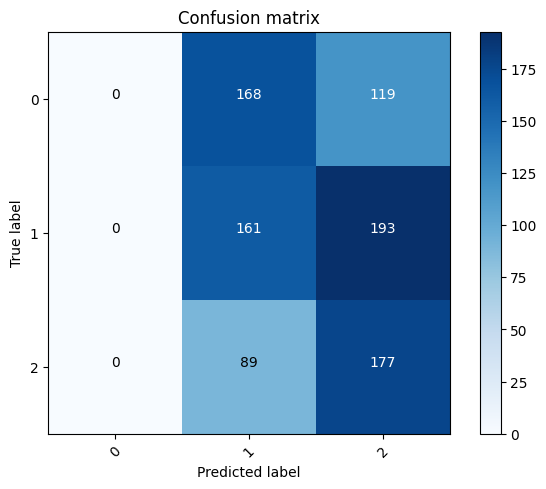

In [ ]:

class_list = [str(i) for i in range(3)]
cm = confusion_matrix(y_test_new, y_pred_label)
plot_confusion_matrix(cm, classes=class_list)

In [ ]:
from sklearn.metrics import accuracy_score, recall_score, precision_score, auc, roc_auc_score, roc_curve,f1_score
from sklearn.metrics import confusion_matrix, classification_report, f1_score

comparison_dict = {}
def metric_calculation(trainLabel,y_pred,classifier_name_abv):

    comparison_dict[classifier_name_abv] = [
        accuracy_score(trainLabel, y_pred),
        precision_score(trainLabel, y_pred,average="macro"),
        recall_score(trainLabel, y_pred,average="macro"),
        f1_score(trainLabel, y_pred,average="macro")

    ]



In [ ]:
y_test_new = np.array(y_test_new)
y_test_new

array([1, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1,
       0, 2, 2, 0, 0, 2, 2, 1, 2, 2, 0, 0, 1, 0, 2, 0, 1, 1, 0, 1, 0, 0,
       2, 2, 1, 2, 1, 2, 0, 0, 0, 0, 0, 2, 0, 2, 0, 0, 2, 1, 2, 1, 0, 2,
       0, 1, 0, 2, 0, 2, 2, 2, 0, 0, 0, 2, 0, 1, 2, 1, 2, 1, 1, 0, 2, 0,
       1, 0, 1, 2, 1, 1, 0, 2, 0, 0, 1, 1, 1, 2, 1, 1, 2, 2, 1, 1, 0, 0,
       2, 1, 2, 1, 0, 2, 1, 0, 0, 0, 2, 1, 0, 1, 2, 1, 2, 2, 2, 0, 1, 1,
       2, 2, 0, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 2, 2, 2, 1, 1, 1, 0, 2, 1,
       2, 0, 1, 1, 0, 1, 0, 2, 0, 2, 0, 0, 1, 2, 1, 0, 1, 0, 2, 2, 2, 1,
       1, 2, 2, 0, 2, 1, 2, 0, 0, 2, 1, 1, 2, 2, 0, 1, 0, 1, 2, 1, 0, 2,
       0, 2, 1, 2, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 2, 1, 2, 2, 1, 1,
       1, 0, 1, 1, 2, 1, 0, 1, 1, 1, 1, 2, 2, 2, 2, 0, 0, 1, 1, 1, 1, 0,
       1, 2, 0, 0, 0, 2, 1, 1, 0, 1, 1, 0, 1, 2, 0, 2, 0, 2, 2, 1, 0, 2,
       1, 0, 1, 1, 1, 2, 1, 1, 0, 2, 2, 0, 2, 2, 2, 2, 0, 0, 0, 1, 0, 1,
       2, 1, 0, 0, 2, 2, 1, 2, 2, 0, 0, 0, 0, 2, 2,

In [ ]:
y_pred_label=np.array(y_pred_label)
y_pred_label

array([2, 2, 2, 1, 2, 2, 2, 1, 1, 1, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 1,
       1, 2, 2, 1, 2, 1, 1, 1, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 1, 1, 1, 1,
       2, 2, 1, 1, 1, 1, 2, 1, 2, 2, 1, 1, 1, 1, 1, 1, 2, 1, 2, 2, 2, 2,
       2, 2, 1, 2, 1, 2, 1, 2, 2, 1, 1, 1, 2, 2, 2, 1, 2, 2, 2, 1, 2, 1,
       1, 2, 2, 1, 2, 1, 2, 2, 2, 2, 2, 1, 1, 1, 2, 1, 2, 2, 1, 2, 2, 1,
       1, 2, 1, 2, 2, 2, 2, 1, 2, 2, 1, 1, 2, 2, 2, 1, 2, 1, 2, 1, 2, 2,
       2, 2, 2, 2, 1, 1, 1, 2, 2, 2, 1, 1, 2, 2, 2, 2, 2, 1, 2, 2, 2, 1,
       2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2,
       1, 1, 1, 2, 2, 1, 1, 2, 1, 1, 2, 1, 2, 2, 1, 1, 1, 1, 2, 2, 1, 1,
       1, 1, 1, 2, 1, 1, 2, 1, 2, 1, 2, 2, 2, 1, 2, 1, 2, 2, 2, 2, 2, 2,
       1, 2, 2, 2, 1, 2, 1, 2, 2, 1, 1, 2, 1, 2, 2, 1, 2, 2, 2, 1, 2, 1,
       1, 2, 1, 1, 1, 2, 2, 1, 1, 1, 2, 1, 2, 1, 1, 2, 1, 2, 2, 2, 1, 2,
       2, 1, 2, 1, 1, 2, 1, 1, 1, 2, 1, 2, 1, 1, 2, 2, 2, 1, 1, 2, 2, 2,
       2, 1, 1, 2, 2, 2, 2, 1, 1, 1, 1, 2, 2, 2, 1,

In [ ]:
metric_calculation(y_test_new,y_pred_label,classifier_name_abv="DenseNet")

### **Machine Learning classifier based classify the image**

In [ ]:
def converimage2Feature(data_input):

    test_ID=data_input["patientId"].values
    Y_label=data_input["class"].values

    train_image_feature = []
    Y_label_new  =[]
    image_batch = np.zeros((1,IMG_WIDTH,IMG_HEIGHT,1))

    for i in range(len(test_ID)):
        sample = training_image_path+test_ID[i]

        img = read_Image(sample+".dcm")
        image_resized = cv2.resize(img, (32,32))
        train_image_feature.append(image_resized.flatten())
        Y_label_new.append(LabelDict[Y_label[i]])
    return np.array(train_image_feature),np.array(Y_label_new)

In [ ]:
train_feature,y_train_feat = converimage2Feature(train_new)

valid_feature,y_valid_feat = converimage2Feature(valid_new)

In [ ]:
from xgboost import XGBClassifier

# Updated initialization with eval_metric and early_stopping_rounds
clf = XGBClassifier(
    n_estimators=1000,
    eval_metric="auc",
    early_stopping_rounds=10
)

evaluation = [(train_feature, y_train_feat), (valid_feature, y_valid_feat)]

# Removed eval_metric and early_stopping_rounds from fit call
clf.fit(
    train_feature,
    y_train_feat,
    eval_set=evaluation,
    verbose=False
)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=10,
              enable_categorical=False, eval_metric='auc', feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=1000,
              n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
test_image_feature = []
#Y_label_new  =[]
for i in range(len(test_data)):
    sample = training_image_path+test_data[i]

    img = read_Image(sample+".dcm")
    image_resized = cv2.resize(img, (32,32))
    test_image_feature.append(image_resized.flatten())
    #Y_label_new.append(LabelDict[Y_label[i]])

In [ ]:
xg_test_pred = clf.predict(test_image_feature)
xg_test_pred

array([1, 2, 2, 1, 2, 2, 2, 1, 2, 1, 2, 1, 1, 1, 1, 1, 1, 2, 0, 1, 2, 1,
       0, 2, 2, 0, 1, 2, 2, 1, 2, 2, 0, 0, 2, 1, 2, 1, 1, 1, 0, 0, 2, 0,
       2, 2, 1, 2, 1, 1, 0, 0, 1, 2, 0, 1, 1, 2, 0, 0, 1, 0, 2, 1, 0, 2,
       0, 1, 0, 2, 0, 1, 2, 2, 0, 0, 0, 2, 0, 2, 1, 1, 2, 2, 2, 0, 2, 1,
       1, 0, 2, 0, 0, 1, 0, 2, 0, 0, 2, 0, 1, 2, 1, 1, 2, 1, 0, 2, 0, 0,
       1, 2, 2, 0, 1, 1, 2, 1, 0, 1, 1, 1, 0, 2, 2, 2, 2, 2, 2, 0, 1, 1,
       2, 1, 0, 2, 0, 1, 1, 0, 2, 1, 1, 1, 1, 2, 2, 1, 1, 0, 1, 0, 2, 0,
       2, 0, 0, 1, 0, 1, 1, 1, 0, 2, 1, 0, 1, 2, 0, 0, 0, 0, 1, 1, 2, 0,
       1, 2, 2, 0, 2, 1, 2, 1, 0, 1, 1, 1, 2, 1, 0, 1, 1, 1, 1, 1, 0, 2,
       0, 1, 1, 2, 0, 0, 0, 0, 2, 1, 1, 0, 2, 2, 1, 0, 2, 1, 2, 1, 1, 1,
       1, 1, 1, 1, 2, 1, 0, 2, 1, 1, 1, 2, 1, 2, 1, 0, 1, 1, 0, 1, 1, 0,
       1, 2, 1, 1, 1, 1, 0, 2, 0, 1, 1, 0, 2, 2, 0, 2, 0, 0, 2, 2, 0, 2,
       1, 0, 2, 1, 2, 2, 0, 1, 0, 2, 2, 0, 2, 2, 1, 1, 0, 0, 2, 1, 2, 1,
       2, 1, 0, 0, 2, 2, 0, 1, 2, 0, 0, 0, 0, 2, 2,

### **Calculate the metrics of XGBoost model**

In [ ]:
metric_calculation(y_test_new,xg_test_pred,"XGBoost")

Confusion matrix, without normalization


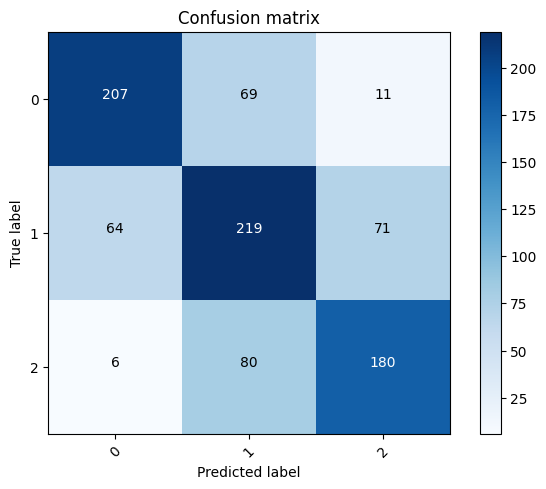

In [ ]:
class_list = [str(i) for i in range(3)]
cm = confusion_matrix(y_test_new, xg_test_pred)
plot_confusion_matrix(cm, classes=class_list)

In [ ]:
## Creating the training metrics datasheet
comparison_matrix = {}
for key, value in comparison_dict.items():
    comparison_matrix[str(key)] = value[0:5]

testDataMetrics = pd.DataFrame(comparison_matrix,
                            index=['Accuracy', 'Precision', 'Recall','F1_score']).T

testDataMetrics.head(5)

,Accuracy,Precision,Recall,F1_score
DenseNet,0.372657,0.249044,0.373405,0.295324
XGBoost,0.668137,0.676475,0.672197,0.674170


In [ ]:
model.save('pneumonia_detection.keras')

In [ ]:
my_model = model.save('pneumonia_detection.h5')

First, let's create a requirements.txt file which will specify all the Python libraries needed for our application.

First, install the huggingface_hub library.

In [2]:
!pip install huggingface_hub

Next, log in to Hugging Face Hub using your API token. You can generate a new token with 'write' access from your Hugging Face settings: https://huggingface.co/settings/tokens. Please add this token as a Colab secret named HF_TOKEN.



In [4]:
from huggingface_hub import login
from google.colab import userdata

# Get Hugging Face token from Colab secrets
HUGGING_FACE_TOKEN = userdata.get('HF_TOKEN')

if HUGGING_FACE_TOKEN:
    login(token=HUGGING_FACE_TOKEN)
    print("Successfully logged into Hugging Face Hub!")
else:
    print("Hugging Face token not found in Colab secrets. Please add it as 'HF_TOKEN'.")

Successfully logged into Hugging Face Hub!


Now, we will push the Dockerfile, model, and application files to your Hugging Face Space.

Finally, we will create the Dockerfile. This file describes how to build the Docker image for your application, including setting up the environment, installing dependencies, and running your Gradio app.

In [3]:
%%writefile Dockerfile
FROM python:3.9-slim

WORKDIR /app

COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt

COPY pneumonia_detection.keras .
COPY app.py .

EXPOSE 7860

CMD ["python", "app.py"]

Writing Dockerfile


Next, we'll create the `app.py` file. This will contain the Gradio interface to interact with your model.

In [2]:
%%writefile app.py
import tensorflow as tf
import numpy as np
import gradio as gr
from PIL import Image

# Load the trained model
model = tf.keras.models.load_model('pneumonia_detection.keras')

# Define the image size the model expects
IMG_HEIGHT = 256
IMG_WIDTH = 256

# Function to preprocess the image and make a prediction
def predict_pneumonia(image):
    if image is None:
        return "Please upload an image."

    # Convert PIL Image to numpy array
    image_array = np.asarray(image.convert('L')) # Convert to grayscale

    # Resize image to the expected dimensions
    image_array = Image.fromarray(image_array).resize((IMG_WIDTH, IMG_HEIGHT))
    image_array = np.asarray(image_array)

    # Add batch and channel dimensions (for grayscale, it's (1, height, width, 1))
    img_batch = np.expand_dims(image_array, axis=0)
    img_batch = np.expand_dims(img_batch, axis=-1)

    # The model expects normalized pixel values (0-1), which is handled by Rescaling layer in the model
    # So, no manual normalization (e.g., img_batch / 255.0) is needed here if Rescaling layer is in model.

    prediction = model.predict(img_batch)[0][0]

    # Define class labels
    class_names = ['NORMAL', 'PNEUMONIA']

    # Get the predicted class and confidence
    if prediction > 0.5:
        predicted_class = 'PNEUMONIA'
        confidence = prediction
    else:
        predicted_class = 'NORMAL'
        confidence = 1 - prediction

    return f"Prediction: {predicted_class} (Confidence: {confidence:.2f})"

# Set up the Gradio interface
iface = gr.Interface(
    fn=predict_pneumonia,
    inputs=gr.Image(type="pil", label="Upload Chest X-ray Image"),
    outputs="text",
    title="Pneumonia Detection from Chest X-ray",
    description="Upload a chest X-ray image to check for pneumonia. The model will output 'Pneumonia' or 'Normal' along with a confidence score."
)

# Launch the Gradio interface
iface.launch(share=True)

Writing app.py


In [5]:
%%writefile requirements.txt
tensorflow
numpy
Pillow
gradio
scikit-learn

Overwriting requirements.txt


In [6]:
from huggingface_hub import HfApi, create_repo
import os

# Define your Hugging Face Space name and local files
HF_SPACE_NAME = "u2jyothibhat/PneumoniaDetectionPublic"
LOCAL_FILES = ["Dockerfile", "requirements.txt", "app.py", "pneumonia_detection.keras"]
COMMIT_MESSAGE = "Add Dockerfile, app.py, requirements.txt, and model for Gradio app"
# Ensure HUGGING_FACE_TOKEN is set as an environment variable or pass it directly
# HUGGING_FACE_TOKEN = "your_hf_token_here"

# Initialize the HfApi
api = HfApi()

# Login (optional if token is passed to HfApi or set as env var)
# from huggingface_hub import login
# login(token=HUGGING_FACE_TOKEN)

try:
    # Ensure the repository exists, create it if it doesn't
    # Set repo_type="space" for a Hugging Face Space
    create_repo(repo_id=HF_SPACE_NAME, repo_type="space", space_sdk='gradio', exist_ok=True, token=os.environ.get("HUGGING_FACE_TOKEN"))

    # Upload each file individually
    for file_path in LOCAL_FILES:
        if os.path.exists(file_path):
            api.upload_file(
                path_or_fileobj=file_path,
                path_in_repo=file_path, # Upload to the root of the repo
                repo_id=HF_SPACE_NAME,
                repo_type="space",
                commit_message=f"Upload {file_path} - {COMMIT_MESSAGE}",
                token=os.environ.get("HUGGING_FACE_TOKEN")
            )
            print(f"Uploaded {file_path}")
        else:
            print(f"Warning: {file_path} not found locally.")

    print(f"\nFiles pushed to Hugging Face Space: https://huggingface.co/spaces/{HF_SPACE_NAME}")

except Exception as e:
    print(f"An error occurred: {e}")

Uploaded Dockerfile
Uploaded requirements.txt
Uploaded app.py


Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  pneumonia_detection.keras   :  33%|###3      | 16.0MB / 48.2MB            

Uploaded pneumonia_detection.keras

Files pushed to Hugging Face Space: https://huggingface.co/spaces/u2jyothibhat/PneumoniaDetectionPublic


The files, including Dockerfile, requirements.txt, app.py, and pneumonia_detection.keras model, have been successfully pushed to Hugging Face Space: https://huggingface.co/spaces/u2jyothibhat/PneumoniaDetectionPublic

You can now visit this link to see your deployed Gradio application.